In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter
import random
import shutil

# ============================================================
# PROJECT PATHS
# ============================================================

# Notebook is inside:
# D:\sih-rdd2022\notebooks\
PROJECT_ROOT = Path("..").resolve()

DATASETS_ROOT = PROJECT_ROOT / "datasets"

# Source datasets
INDIA_ROOT = DATASETS_ROOT / "India"
JAPAN_ROOT = DATASETS_ROOT / "Japan"
NORWAY_ROOT = DATASETS_ROOT / "Norway"

# Output dataset
OUTPUT_ROOT = DATASETS_ROOT / "processed" / "rdd4"

print("Project root :", PROJECT_ROOT)
print("Datasets     :", DATASETS_ROOT)
print("Output       :", OUTPUT_ROOT)

print("\nSource datasets:")
print("India  :", INDIA_ROOT.exists())
print("Japan  :", JAPAN_ROOT.exists())
print("Norway :", NORWAY_ROOT.exists())

Project root : D:\sih-rdd2022
Datasets     : D:\sih-rdd2022\datasets
Output       : D:\sih-rdd2022\datasets\processed\rdd4

Source datasets:
India  : True
Japan  : True
Norway : True


In [2]:
# ============================================================
# VERIFY RDD2022 SOURCE STRUCTURE
# ============================================================

sources = {
    "India": INDIA_ROOT,
    "Japan": JAPAN_ROOT,
    "Norway": NORWAY_ROOT
}

for country, root in sources.items():

    train_images = root / "train" / "images"
    train_xmls = root / "train" / "annotations" / "xmls"

    print("=" * 60)
    print(country.upper())
    print("=" * 60)

    print("Train images:")
    print(" ", train_images)
    print("  Exists:", train_images.exists())

    print("\nTrain annotations:")
    print(" ", train_xmls)
    print("  Exists:", train_xmls.exists())

    if train_images.exists():
        image_count = sum(1 for f in train_images.iterdir() if f.is_file())
        print("\nImage files:", image_count)

    if train_xmls.exists():
        xml_count = len(list(train_xmls.glob("*.xml")))
        print("XML files  :", xml_count)

    print()
    

INDIA
Train images:
  D:\sih-rdd2022\datasets\India\train\images
  Exists: True

Train annotations:
  D:\sih-rdd2022\datasets\India\train\annotations\xmls
  Exists: True

Image files: 7706
XML files  : 7706

JAPAN
Train images:
  D:\sih-rdd2022\datasets\Japan\train\images
  Exists: True

Train annotations:
  D:\sih-rdd2022\datasets\Japan\train\annotations\xmls
  Exists: True

Image files: 10506
XML files  : 10506

NORWAY
Train images:
  D:\sih-rdd2022\datasets\Norway\train\images
  Exists: True

Train annotations:
  D:\sih-rdd2022\datasets\Norway\train\annotations\xmls
  Exists: True

Image files: 8161
XML files  : 8161



In [3]:
# ============================================================
# RDD2022 — FOUR CLASS DATA ANALYSIS
# ============================================================

TARGET_CLASSES = {
    "D00": 0,   # Longitudinal crack
    "D10": 1,   # Transverse crack
    "D20": 2,   # Alligator crack
    "D40": 3    # Pothole
}

print("=" * 70)
print("RDD2022 — TARGET CLASS ANALYSIS")
print("=" * 70)

overall_instances = Counter()
overall_images_with_target = 0
overall_negative_images = 0

country_results = {}

for country, root in sources.items():

    images_dir = root / "train" / "images"
    xml_dir = root / "train" / "annotations" / "xmls"

    class_counts = Counter()

    images_with_target = 0
    negative_images = 0
    ignored_only_images = 0
    invalid_xml = 0

    for xml_file in xml_dir.glob("*.xml"):

        try:
            tree = ET.parse(xml_file)
            root_xml = tree.getroot()

            objects = root_xml.findall("object")

            target_found = False

            for obj in objects:

                name = obj.find("name")

                if name is None:
                    continue

                class_name = name.text.strip()

                if class_name in TARGET_CLASSES:
                    class_counts[class_name] += 1
                    overall_instances[class_name] += 1
                    target_found = True

            if target_found:
                images_with_target += 1
                overall_images_with_target += 1

            elif len(objects) == 0:
                negative_images += 1
                overall_negative_images += 1

            else:
                # Image contains annotations, but only
                # classes that we are excluding.
                ignored_only_images += 1

        except Exception:
            invalid_xml += 1

    country_results[country] = {
        "instances": class_counts,
        "images_with_target": images_with_target,
        "negative_images": negative_images,
        "ignored_only_images": ignored_only_images,
        "invalid_xml": invalid_xml
    }


    # --------------------------------------------------------
    # COUNTRY RESULTS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(country.upper())
    print("=" * 70)

    print("Images containing target damage :", images_with_target)
    print("Negative images                :", negative_images)
    print("Images with only excluded data :", ignored_only_images)
    print("Invalid XML                    :", invalid_xml)

    print("\nTarget class instances:")

    for class_name in TARGET_CLASSES:

        count = class_counts[class_name]

        print(f"{class_name:<5} : {count:>7}")


# ============================================================
# OVERALL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("COMBINED RDD2022 — TARGET CLASSES")
print("=" * 70)

print("\nClass distribution:")

total_target_instances = sum(overall_instances.values())

for class_name in TARGET_CLASSES:

    count = overall_instances[class_name]

    percentage = (
        count / total_target_instances * 100
        if total_target_instances > 0
        else 0
    )

    print(
        f"{class_name:<5} : "
        f"{count:>7} instances "
        f"({percentage:>6.2f}%)"
    )

print("\nTotal target instances :", total_target_instances)
print("Images with target     :", overall_images_with_target)
print("Negative images        :", overall_negative_images)

RDD2022 — TARGET CLASS ANALYSIS

INDIA
Images containing target damage : 3223
Negative images                : 3921
Images with only excluded data : 562
Invalid XML                    : 0

Target class instances:
D00   :    1555
D10   :      68
D20   :    2021
D40   :    3187

JAPAN
Images containing target damage : 7900
Negative images                : 794
Images with only excluded data : 1812
Invalid XML                    : 0

Target class instances:
D00   :    4049
D10   :    3979
D20   :    6199
D40   :    2243

NORWAY
Images containing target damage : 2914
Negative images                : 5247
Images with only excluded data : 0
Invalid XML                    : 0

Target class instances:
D00   :    8570
D10   :    1730
D20   :     468
D40   :     461

COMBINED RDD2022 — TARGET CLASSES

Class distribution:
D00   :   14174 instances ( 41.05%)
D10   :    5777 instances ( 16.73%)
D20   :    8688 instances ( 25.16%)
D40   :    5891 instances ( 17.06%)

Total target instances : 34530
Im

In [4]:
# ============================================================
# RDD4 DATASET PLAN
# ============================================================

TARGET_CLASSES = {
    "D00": 0,
    "D10": 1,
    "D20": 2,
    "D40": 3
}

# Number of true negative images we want
NEGATIVE_LIMIT = 3000

# Train / validation split
TRAIN_RATIO = 0.80
VAL_RATIO = 0.20

print("=" * 70)
print("RDD4 DATASET CONSTRUCTION PLAN")
print("=" * 70)

print("\nTarget classes:")
for name, class_id in TARGET_CLASSES.items():
    print(f"  {class_id} -> {name}")

print("\nImages:")
print(f"  Target-damage images : {overall_images_with_target}")
print(f"  True negative images : {overall_negative_images}")
print(f"  Negative images used : {NEGATIVE_LIMIT}")

total_images = overall_images_with_target + NEGATIVE_LIMIT

train_count = int(total_images * TRAIN_RATIO)
val_count = total_images - train_count

print("\nExpected final dataset:")
print(f"  Total images : {total_images}")
print(f"  Train       : {train_count}")
print(f"  Validation  : {val_count}")

print("\nExcluded:")
print("  Images containing only non-target classes")
print("  These will NOT be treated as negatives.")

print("\n" + "=" * 70)
print("PLAN READY")
print("=" * 70)

RDD4 DATASET CONSTRUCTION PLAN

Target classes:
  0 -> D00
  1 -> D10
  2 -> D20
  3 -> D40

Images:
  Target-damage images : 14037
  True negative images : 9962
  Negative images used : 3000

Expected final dataset:
  Total images : 17037
  Train       : 13629
  Validation  : 3408

Excluded:
  Images containing only non-target classes
  These will NOT be treated as negatives.

PLAN READY


In [5]:
# ============================================================
# CELL 5 — BUILD RDD4 YOLO DATASET
# ============================================================

import random
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

TARGET_CLASSES = {
    "D00": 0,
    "D10": 1,
    "D20": 2,
    "D40": 3
}

NEGATIVE_LIMIT = 3000
TRAIN_RATIO = 0.80

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# ------------------------------------------------------------
# OUTPUT DIRECTORIES
# ------------------------------------------------------------

OUTPUT_ROOT = DATASETS_ROOT / "processed" / "rdd4"

TRAIN_IMAGES = OUTPUT_ROOT / "images" / "train"
VAL_IMAGES = OUTPUT_ROOT / "images" / "val"

TRAIN_LABELS = OUTPUT_ROOT / "labels" / "train"
VAL_LABELS = OUTPUT_ROOT / "labels" / "val"

for directory in [
    TRAIN_IMAGES,
    VAL_IMAGES,
    TRAIN_LABELS,
    VAL_LABELS
]:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("RDD4 DATASET BUILD")
print("=" * 70)

print("\nOutput:")
print(OUTPUT_ROOT)

# ------------------------------------------------------------
# SOURCE DATA
# ------------------------------------------------------------

sources = {
    "India": INDIA_ROOT,
    "Japan": JAPAN_ROOT,
    "Norway": NORWAY_ROOT
}

# ------------------------------------------------------------
# COLLECT IMAGE/XML PAIRS
# ------------------------------------------------------------

target_samples = []
negative_samples = []

total_xml = 0
invalid_xml = 0

class_instance_counts = Counter()

print("\nScanning XML annotations...")

for country, root in sources.items():

    images_dir = root / "train" / "images"
    xml_dir = root / "train" / "annotations" / "xmls"

    country_target = 0
    country_negative = 0

    for xml_file in xml_dir.glob("*.xml"):

        total_xml += 1

        try:
            tree = ET.parse(xml_file)
            annotation = tree.getroot()

        except Exception:
            invalid_xml += 1
            continue

        filename_element = annotation.find("filename")

        if filename_element is None:
            continue

        original_filename = filename_element.text.strip()

        image_path = images_dir / original_filename

        if not image_path.exists():
            continue

        # ----------------------------------------------------
        # READ IMAGE SIZE
        # ----------------------------------------------------

        size = annotation.find("size")

        if size is None:
            continue

        width_element = size.find("width")
        height_element = size.find("height")

        if width_element is None or height_element is None:
            continue

        width = float(width_element.text)
        height = float(height_element.text)

        # ----------------------------------------------------
        # READ TARGET OBJECTS
        # ----------------------------------------------------

        objects = []

        for obj in annotation.findall("object"):

            name_element = obj.find("name")

            if name_element is None:
                continue

            class_name = name_element.text.strip()

            if class_name not in TARGET_CLASSES:
                continue

            bbox = obj.find("bndbox")

            if bbox is None:
                continue

            xmin = float(bbox.find("xmin").text)
            ymin = float(bbox.find("ymin").text)
            xmax = float(bbox.find("xmax").text)
            ymax = float(bbox.find("ymax").text)

            # ------------------------------------------------
            # CLAMP COORDINATES
            # ------------------------------------------------

            xmin = max(0.0, min(xmin, width))
            xmax = max(0.0, min(xmax, width))

            ymin = max(0.0, min(ymin, height))
            ymax = max(0.0, min(ymax, height))

            # Invalid box check
            if xmax <= xmin or ymax <= ymin:
                continue

            objects.append({
                "class_id": TARGET_CLASSES[class_name],
                "class_name": class_name,
                "xmin": xmin,
                "ymin": ymin,
                "xmax": xmax,
                "ymax": ymax
            })

            class_instance_counts[class_name] += 1

        # ----------------------------------------------------
        # TARGET IMAGE
        # ----------------------------------------------------

        if len(objects) > 0:

            target_samples.append({
                "country": country,
                "image_path": image_path,
                "xml_path": xml_file,
                "filename": original_filename,
                "width": width,
                "height": height,
                "objects": objects
            })

            country_target += 1

        # ----------------------------------------------------
        # TRUE NEGATIVE IMAGE
        # ----------------------------------------------------

        else:

            # Only consider images with zero annotated objects
            # as true negatives.
            all_objects = annotation.findall("object")

            if len(all_objects) == 0:

                negative_samples.append({
                    "country": country,
                    "image_path": image_path,
                    "xml_path": xml_file,
                    "filename": original_filename,
                    "width": width,
                    "height": height,
                    "objects": []
                })

                country_negative += 1

    print(
        f"{country:<10} | "
        f"Target images: {country_target:>5} | "
        f"Negatives: {country_negative:>5}"
    )

# ------------------------------------------------------------
# SAMPLE NEGATIVES
# ------------------------------------------------------------

random.shuffle(negative_samples)

selected_negatives = negative_samples[:NEGATIVE_LIMIT]

print("\n" + "=" * 70)
print("DATA SELECTION")
print("=" * 70)

print("Target images :", len(target_samples))
print("Available negatives :", len(negative_samples))
print("Selected negatives :", len(selected_negatives))

# ------------------------------------------------------------
# COMBINE
# ------------------------------------------------------------

all_samples = target_samples + selected_negatives

random.shuffle(all_samples)

print("\nTotal selected images:", len(all_samples))

# ------------------------------------------------------------
# TRAIN / VALIDATION SPLIT
# ------------------------------------------------------------

split_index = int(len(all_samples) * TRAIN_RATIO)

train_samples = all_samples[:split_index]
val_samples = all_samples[split_index:]

print("Training images   :", len(train_samples))
print("Validation images :", len(val_samples))

# ------------------------------------------------------------
# CONVERT TO YOLO
# ------------------------------------------------------------

def convert_bbox_to_yolo(obj, width, height):

    xmin = obj["xmin"]
    ymin = obj["ymin"]
    xmax = obj["xmax"]
    ymax = obj["ymax"]

    x_center = ((xmin + xmax) / 2) / width
    y_center = ((ymin + ymax) / 2) / height

    box_width = (xmax - xmin) / width
    box_height = (ymax - ymin) / height

    return (
        obj["class_id"],
        x_center,
        y_center,
        box_width,
        box_height
    )


# ------------------------------------------------------------
# COPY FUNCTION
# ------------------------------------------------------------

def process_samples(samples, image_output, label_output, split_name):

    processed = 0
    failed = 0

    class_counts = Counter()

    for sample in samples:

        try:

            country = sample["country"]
            original_filename = sample["filename"]

            # Prevent filename collisions
            new_filename = f"{country}_{original_filename}"

            destination_image = image_output / new_filename

            label_filename = Path(new_filename).stem + ".txt"
            destination_label = label_output / label_filename

            # Copy image
            shutil.copy2(
                sample["image_path"],
                destination_image
            )

            # Create YOLO label
            with open(
                destination_label,
                "w",
                encoding="utf-8"
            ) as f:

                for obj in sample["objects"]:

                    (
                        class_id,
                        x_center,
                        y_center,
                        box_width,
                        box_height
                    ) = convert_bbox_to_yolo(
                        obj,
                        sample["width"],
                        sample["height"]
                    )

                    f.write(
                        f"{class_id} "
                        f"{x_center:.6f} "
                        f"{y_center:.6f} "
                        f"{box_width:.6f} "
                        f"{box_height:.6f}\n"
                    )

                    class_counts[obj["class_name"]] += 1

            processed += 1

        except Exception as e:

            failed += 1
            print(
                f"FAILED: {sample['filename']} | {e}"
            )

    print(
        f"\n{split_name.upper()} COMPLETE"
    )

    print("Processed:", processed)
    print("Failed   :", failed)

    return class_counts


# ------------------------------------------------------------
# PROCESS TRAIN
# ------------------------------------------------------------

train_counts = process_samples(
    train_samples,
    TRAIN_IMAGES,
    TRAIN_LABELS,
    "train"
)

# ------------------------------------------------------------
# PROCESS VALIDATION
# ------------------------------------------------------------

val_counts = process_samples(
    val_samples,
    VAL_IMAGES,
    VAL_LABELS,
    "validation"
)

# ------------------------------------------------------------
# CREATE data.yaml
# ------------------------------------------------------------

yaml_path = OUTPUT_ROOT / "data.yaml"

yaml_content = f"""path: {OUTPUT_ROOT.as_posix()}
train: images/train
val: images/val

names:
  0: D00
  1: D10
  2: D20
  3: D40
"""

with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RDD4 DATASET BUILD COMPLETE")
print("=" * 70)

print("\nDataset:")
print(OUTPUT_ROOT)

print("\nTrain images :", len(list(TRAIN_IMAGES.iterdir())))
print("Train labels :", len(list(TRAIN_LABELS.iterdir())))

print("\nValidation images :", len(list(VAL_IMAGES.iterdir())))
print("Validation labels :", len(list(VAL_LABELS.iterdir())))

print("\nTrain class instances:")
for cls in TARGET_CLASSES:
    print(f"{cls}: {train_counts[cls]}")

print("\nValidation class instances:")
for cls in TARGET_CLASSES:
    print(f"{cls}: {val_counts[cls]}")

print("\ndata.yaml:")
print(yaml_path)

RDD4 DATASET BUILD

Output:
D:\sih-rdd2022\datasets\processed\rdd4

Scanning XML annotations...
India      | Target images:  3223 | Negatives:  3921
Japan      | Target images:  7900 | Negatives:   794
Norway     | Target images:  2914 | Negatives:  5247

DATA SELECTION
Target images : 14037
Available negatives : 9962
Selected negatives : 3000

Total selected images: 17037
Training images   : 13629
Validation images : 3408

TRAIN COMPLETE
Processed: 13629
Failed   : 0

VALIDATION COMPLETE
Processed: 3408
Failed   : 0

RDD4 DATASET BUILD COMPLETE

Dataset:
D:\sih-rdd2022\datasets\processed\rdd4

Train images : 13629
Train labels : 13629

Validation images : 3408
Validation labels : 3408

Train class instances:
D00: 11268
D10: 4628
D20: 6962
D40: 4675

Validation class instances:
D00: 2906
D10: 1149
D20: 1725
D40: 1216

data.yaml:
D:\sih-rdd2022\datasets\processed\rdd4\data.yaml


In [6]:
# ============================================================
# CELL 6 — RDD4 DATASET INTEGRITY CHECK
# ============================================================

from PIL import Image

print("=" * 70)
print("RDD4 DATASET INTEGRITY CHECK")
print("=" * 70)

splits = {
    "train": (TRAIN_IMAGES, TRAIN_LABELS),
    "val": (VAL_IMAGES, VAL_LABELS)
}

allowed_classes = {0, 1, 2, 3}

total_errors = 0

for split_name, (image_dir, label_dir) in splits.items():

    print("\n" + "=" * 70)
    print(split_name.upper())
    print("=" * 70)

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    print("Images:", len(images))
    print("Labels:", len(labels))

    # --------------------------------------------------------
    # MATCHING FILES
    # --------------------------------------------------------

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))

    if missing_labels:
        total_errors += len(missing_labels)
        print("Examples:", list(missing_labels)[:5])

    if missing_images:
        total_errors += len(missing_images)
        print("Examples:", list(missing_images)[:5])

    # --------------------------------------------------------
    # CHECK LABEL CONTENT
    # --------------------------------------------------------

    invalid_class = 0
    invalid_values = 0
    malformed_lines = 0
    empty_labels = 0
    valid_labels = 0

    for label_file in labels:

        with open(label_file, "r", encoding="utf-8") as f:
            lines = [line.strip() for line in f if line.strip()]

        # Empty label = negative image
        if len(lines) == 0:
            empty_labels += 1
            continue

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                malformed_lines += 1
                continue

            try:
                class_id = int(parts[0])

                values = [float(x) for x in parts[1:]]

            except ValueError:
                malformed_lines += 1
                continue

            # Class check
            if class_id not in allowed_classes:
                invalid_class += 1

            # YOLO normalized coordinate check
            if not all(0.0 <= x <= 1.0 for x in values):
                invalid_values += 1

            # Width/height must be positive
            if values[2] <= 0 or values[3] <= 0:
                invalid_values += 1

            else:
                valid_labels += 1

    print("\nLabel checks:")
    print("Empty labels (negatives):", empty_labels)
    print("Valid annotations:", valid_labels)
    print("Invalid class IDs:", invalid_class)
    print("Invalid coordinates:", invalid_values)
    print("Malformed lines:", malformed_lines)

    total_errors += (
        invalid_class +
        invalid_values +
        malformed_lines
    )

    # --------------------------------------------------------
    # IMAGE READABILITY
    # --------------------------------------------------------

    corrupted_images = 0

    for image_file in images:

        try:
            with Image.open(image_file) as img:
                img.verify()

        except Exception:
            corrupted_images += 1
            print("Corrupted:", image_file.name)

    print("Corrupted images:", corrupted_images)

    total_errors += corrupted_images


# ============================================================
# FINAL RESULT
# ============================================================

print("\n" + "=" * 70)
print("FINAL INTEGRITY RESULT")
print("=" * 70)

if total_errors == 0:
    print("✅ DATASET PASSED ALL INTEGRITY CHECKS")
else:
    print(f"❌ TOTAL ERRORS FOUND: {total_errors}")

RDD4 DATASET INTEGRITY CHECK

TRAIN
Images: 13629
Labels: 13629
Missing labels: 0
Missing images: 0

Label checks:
Empty labels (negatives): 2395
Valid annotations: 27533
Invalid class IDs: 0
Invalid coordinates: 0
Malformed lines: 0
Corrupted images: 0

VAL
Images: 3408
Labels: 3408
Missing labels: 0
Missing images: 0

Label checks:
Empty labels (negatives): 605
Valid annotations: 6996
Invalid class IDs: 0
Invalid coordinates: 0
Malformed lines: 0
Corrupted images: 0

FINAL INTEGRITY RESULT
✅ DATASET PASSED ALL INTEGRITY CHECKS


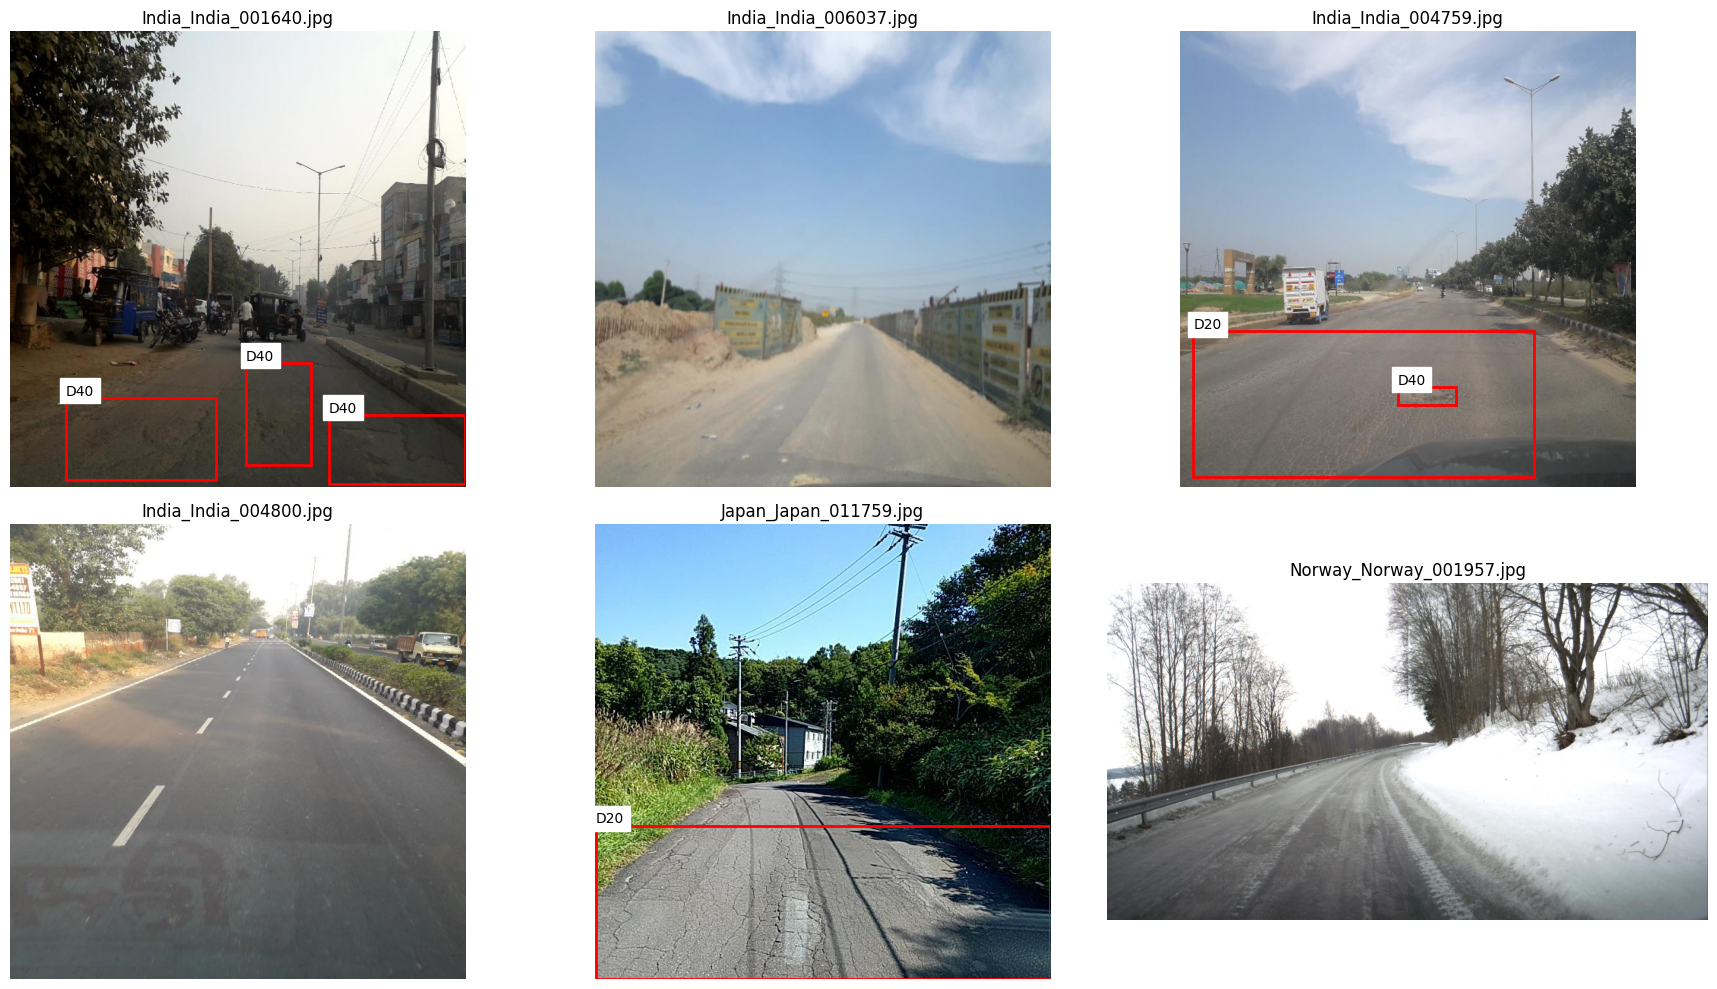

In [7]:
# ============================================================
# CELL 7 — VISUAL CHECK OF YOLO ANNOTATIONS
# ============================================================

import random
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

CLASS_NAMES = {
    0: "D00",
    1: "D10",
    2: "D20",
    3: "D40"
}

# Select random images
image_files = list(TRAIN_IMAGES.glob("*"))
samples = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, samples):

    # Load image
    image = Image.open(image_path)

    width, height = image.size

    ax.imshow(image)

    # Corresponding label
    label_path = TRAIN_LABELS / f"{image_path.stem}.txt"

    if label_path.exists():

        with open(label_path, "r", encoding="utf-8") as f:
            lines = [line.strip() for line in f if line.strip()]

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            x_center = float(parts[1]) * width
            y_center = float(parts[2]) * height
            box_width = float(parts[3]) * width
            box_height = float(parts[4]) * height

            xmin = x_center - box_width / 2
            ymin = y_center - box_height / 2

            rect = patches.Rectangle(
                (xmin, ymin),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                xmin,
                max(0, ymin - 5),
                CLASS_NAMES[class_id],
                fontsize=10,
                backgroundcolor="white"
            )

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()